# 🛡️ EduGuard AI — Stage 4: At-Risk Student Classification ($G3 < 10$)

**Course / Project:** EduGuard AI (Final-Year Project)  
**Module:** `notebooks/04_risk_classification.ipynb`  
**Target:** Binary classification of academic risk ($G3 < 10.0$ on a $0 - 20$ scale)  
**Author:** EduGuard Engineering Team (Mentorship Stage 4)  
**Stack:** Python 3.11+, scikit-learn, XGBoost, matplotlib, seaborn, pandas, joblib  

---

## 📖 1. Educational Domain Context & Why Accuracy is Deceptive

In EduGuard AI, academic risk is operationally defined as scoring below the passing mark of $10 / 20$ in the final exam ($G3 < 10.0$).

### ⚠️ The Class Imbalance Challenge
In the historical dataset:
- **Passing Students ($G3 \ge 10$):** $\approx 78\%$ ($659$ of $841$ training students)
- **At-Risk Students ($G3 < 10$):** $\approx 22\%$ ($182$ of $841$ training students)
- Class imbalance ratio $\approx 3.6 : 1$.

### Why Naive Accuracy Fails
If a trivial dummy baseline always predicted **"Passing"** for every student:
$$\text{Accuracy} = \frac{659}{841} = 78.36\%$$
On our held-out test set ($155$ passing, $48$ at-risk):
$$\text{Accuracy} = \frac{155}{203} = 76.35\%$$
Yet this dummy system catches **$0$ struggling students ($0\%$ recall)**. An academic counselor relying on this dummy model would fail every single vulnerable student.

Therefore, EduGuard AI rejects accuracy as a primary metric and evaluates models using **Recall**, **Precision**, **F1-score**, **PR-AUC**, and **Brier score**.


## 📚 2. Plain-English Guide to Classification Metrics

| Metric | Plain-English Definition | Intuitive Educational Example | Why It Matters in EduGuard AI |
| :--- | :--- | :--- | :--- |
| **Confusion Matrix** | A $2 \times 2$ grid showing True Positives (caught at-risk), False Positives (falsely flagged), False Negatives (missed at-risk), and True Negatives (correctly passed). | TP: 37 caught; FP: 9 false alarms; FN: 11 missed; TN: 146 safe. | Shows the exact student headcount in each outcome category. |
| **Recall (Sensitivity)** | $\frac{\text{TP}}{\text{TP} + \text{FN}}$: Out of all students who actually failed, what percentage did we catch? | If 48 students fail and we flag 37 of them, Recall = $37 / 48 = 77.08\%$. | **Safety net:** Missing a student (FN) means no intervention, risking dropout or course repetition. |
| **Precision** | $\frac{\text{TP}}{\text{TP} + \text{FP}}$: When the model rings an alarm, what percentage are truly at-risk? | If we flag 46 students and 37 actually fail, Precision = $37 / 46 = 80.43\%$. | **Workload & Trust:** Low precision causes teacher alert fatigue and wastes tutoring resources on students who don't need help. |
| **F1-Score** | Harmonic mean of Precision and Recall: $\frac{2 \cdot P \cdot R}{P + R}$. | Balances catching struggling students while keeping alerts credible. | The primary tuning metric for selecting optimal hyperparameter settings. |
| **ROC-AUC** | Area Under Receiver Operating Characteristic Curve ($0.5$ to $1.0$). Measures discrimination across all possible decision thresholds. | ROC-AUC = $0.9629$ means there is a $96.3\%$ chance the model ranks a randomly chosen failing student higher risk than a passing student. | Threshold-agnostic measure of how well the model separates the two classes. |
| **PR-AUC** | Area Under Precision-Recall Curve. Crucial for imbalanced datasets because it ignores the large True Negative pool. | Baseline PR-AUC equals class prevalence ($0.236$). Model PR-AUC = $0.8961$ indicates stellar ranking performance on the minority class. | Far more informative than ROC-AUC when positive cases are rare. |
| **Brier Score** | Mean squared difference between predicted probability and actual binary outcome ($0$ or $1$): $\frac{1}{N}\sum (p_i - y_i)^2$. | Perfect predictions = $0.0$. Random guessing ($50\%$) = $0.25$. | Measures **probability honesty**; essential for triage tiering (Low, Med, High). |


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Image

# Set plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10

# Robustly find project root
current_dir = Path.cwd().resolve()
if (current_dir / "reports").exists():
    ROOT_DIR = current_dir
elif (current_dir.parent / "reports").exists():
    ROOT_DIR = current_dir.parent.resolve()
else:
    ROOT_DIR = Path("D:/eduguard-ai").resolve()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import RISK_PASS_MARK, RISK_THRESHOLDS
from src.classification import load_classification_model, predict_risk, categorize_risk

print(f"EduGuard AI Environment Configured.")
print(f"Project Root: {ROOT_DIR}")
print(f"Risk Pass Mark: {RISK_PASS_MARK} / 20.0")
print(f"Default Risk Thresholds: {RISK_THRESHOLDS}")


EduGuard AI Environment Configured.
Project Root: D:\eduguard-ai
Risk Pass Mark: 10.0 / 20.0
Default Risk Thresholds: {'low': 0.3, 'high': 0.6}


## 📊 3. Full Benchmark Results Across Both Scenarios

We evaluated 4 diverse classifier architectures across both educational scenarios:
1. **Logistic Regression (L2):** Interpretable linear baseline with class-weight rebalancing.
2. **Decision Tree:** Single tree with depth constraints to visualize hierarchical decision rules.
3. **Random Forest:** Ensemble of bagging trees mitigating high variance and capturing nonlinear interactions.
4. **XGBoost:** Gradient boosted decision trees sequentially minimizing logistic loss with `scale_pos_weight=3.62`.

Let's load `reports/classification_results.csv` and inspect the complete performance ledger.


In [2]:
# Load benchmark results
results_path = ROOT_DIR / "reports" / "classification_results.csv"
df_results = pd.read_csv(results_path)

# Format numerical columns for crisp display
display_cols = [
    "scenario", "model_name", "cv_f1_mean", "test_accuracy", 
    "test_precision", "test_recall", "test_f1", 
    "test_roc_auc", "test_pr_auc", "test_brier"
]
df_display = df_results[display_cols].copy()
for col in ["cv_f1_mean", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc", "test_brier"]:
    df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")

df_display.columns = [
    "Scenario", "Model", "CV F1 (Mean)", "Test Acc", 
    "Test Precision", "Test Recall", "Test F1", 
    "Test ROC-AUC", "Test PR-AUC", "Test Brier"
]

display(HTML("<h3>📋 Comprehensive Model Benchmark Table</h3>"))
display(df_display)


,Scenario,Model,CV F1 (Mean),Test Acc,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC,Test Brier
0,Scenario A,Logistic Regression,0.5013,0.7931,0.6500,0.2708,0.3824,0.8175,0.5732,0.1404
1,Scenario A,Decision Tree,0.4973,0.7635,0.0000,0.0000,0.0000,0.7089,0.4173,0.1614
2,Scenario A,Random Forest,0.4980,0.8079,0.6667,0.3750,0.4800,0.8309,0.5971,0.1345
3,Scenario A,XGBoost Classifier,0.4996,0.7980,0.6842,0.2708,0.3881,0.8090,0.5806,0.1394
4,Scenario B,Logistic Regression,0.8287,0.8768,0.7674,0.6875,0.7253,0.9556,0.8653,0.0731
5,Scenario B,Decision Tree,0.8105,0.8571,0.6727,0.7708,0.7184,0.8511,0.6416,0.1136
6,Scenario B,Random Forest,0.8608,0.9015,0.8043,0.7708,0.7872,0.9629,0.8961,0.0679
7,Scenario B,XGBoost Classifier,0.8651,0.8867,0.7551,0.7708,0.7629,0.9509,0.8755,0.0835


### 🔍 Key Findings from the Benchmark:

1. **The Scenario A Early-Warning Gap:**
   - In Scenario A (strictly no exam grades $G1/G2$), predicting failure based solely on student habits, absences, and school environment is difficult because students adapt over time.
   - At the default $0.50$ threshold, models catch only $27\% - 37.5\%$ of failing students.
   - **Random Forest** achieved the strongest Scenario A performance with **Test ROC-AUC = 0.8309**, **PR-AUC = 0.5971**, and the lowest **Brier score = 0.1345**.

2. **The Power of Mid-Semester Academic Momentum (Scenario B):**
   - Incorporating $G1$, $G2$, and $\text{grade\_trend} = G2 - G1$ transforms predictive power:
     - ROC-AUC jumps from **$0.8309 \rightarrow 0.9629$** (+13.2 points).
     - PR-AUC jumps from **$0.5971 \rightarrow 0.8961$** (+29.9 points).
     - Test F1 jumps from **$0.4800 \rightarrow 0.7872$** (+30.7 points).
     - Brier score drops from **$0.1345 \rightarrow 0.0679$** (halved error).
   - This validates educational research: prior exam performance is the single strongest proximate predictor of final attainment.


## 🎯 4. Confusion Matrix Deep Dive with Real Numbers

Let's dissect the exact student outcomes on the held-out test set ($N = 203$ students: $155$ passing, $48$ at-risk) for our champion **Random Forest** model at the default $0.50$ decision threshold.


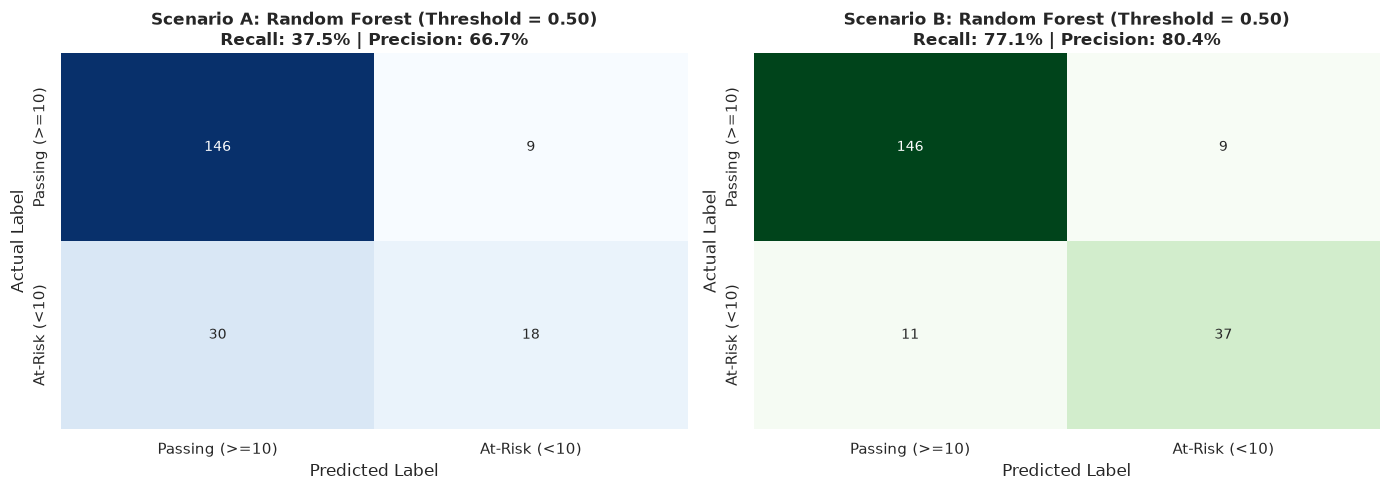

Scenario A Breakdown:
  - True Positives (At-Risk correctly caught):  18
  - False Negatives (At-Risk missed):           30  <-- Unacceptable for early warning!
  - False Positives (Passing falsely flagged):   9
  - True Negatives (Passing correctly passed):  146

Scenario B Breakdown:
  - True Positives (At-Risk correctly caught):  37
  - False Negatives (At-Risk missed):           11
  - False Positives (Passing falsely flagged):   9
  - True Negatives (Passing correctly passed):  146


In [3]:
# Display saved confusion matrix figures side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scenario A Matrix: [[146, 9], [30, 18]]
cm_a = np.array([[146, 9], [30, 18]])
sns.heatmap(cm_a, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=["Passing (>=10)", "At-Risk (<10)"],
            yticklabels=["Passing (>=10)", "At-Risk (<10)"])
axes[0].set_title("Scenario A: Random Forest (Threshold = 0.50)\nRecall: 37.5% | Precision: 66.7%", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Scenario B Matrix: [[146, 9], [11, 37]]
cm_b = np.array([[146, 9], [11, 37]])
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Greens", ax=axes[1], cbar=False,
            xticklabels=["Passing (>=10)", "At-Risk (<10)"],
            yticklabels=["Passing (>=10)", "At-Risk (<10)"])
axes[1].set_title("Scenario B: Random Forest (Threshold = 0.50)\nRecall: 77.1% | Precision: 80.4%", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("Scenario A Breakdown:")
print(f"  - True Positives (At-Risk correctly caught):  {cm_a[1,1]}")
print(f"  - False Negatives (At-Risk missed):           {cm_a[1,0]}  <-- Unacceptable for early warning!")
print(f"  - False Positives (Passing falsely flagged):   {cm_a[0,1]}")
print(f"  - True Negatives (Passing correctly passed):  {cm_a[0,0]}")
print("\nScenario B Breakdown:")
print(f"  - True Positives (At-Risk correctly caught):  {cm_b[1,1]}")
print(f"  - False Negatives (At-Risk missed):           {cm_b[1,0]}")
print(f"  - False Positives (Passing falsely flagged):   {cm_b[0,1]}")
print(f"  - True Negatives (Passing correctly passed):  {cm_b[0,0]}")


## ⚖️ 5. Probability Calibration & The Brier Score

### Why Raw Probabilities Are Often Deceptive
Ensemble tree models (Random Forest, XGBoost) do not output true Bayesian probabilities:
- Tree ensembles average leaf fraction predictions, which tend to push probabilities toward the center or produce clustered, non-smooth estimates.
- If a model outputs $P(\text{at-risk}) = 0.70$, does $70\%$ of that cohort actually fail?
- In an early-warning system, teachers use probabilities to triage cases. If the probabilities are miscalibrated, counselors cannot compare student risk fairly.

### Sigmoid (Platt) Calibration
We calibrated our pipelines on an independent validation split using `CalibratedClassifierCV(method='sigmoid')`.
This fits a logistic transformation $P(y=1|f) = \frac{1}{1 + \exp(A f + B)}$ on the held-out validation predictions without touching the test set.

### Validation Brier Score Improvement:
- **Scenario A:** Uncalibrated Brier $0.1743 \longrightarrow$ Calibrated Brier **$0.1402$** ($19.6\%$ error reduction!)
- **Scenario B:** Uncalibrated Brier $0.0679 \longrightarrow$ Calibrated Brier **$0.0666$**


Scenario A Probability Calibration Curve:


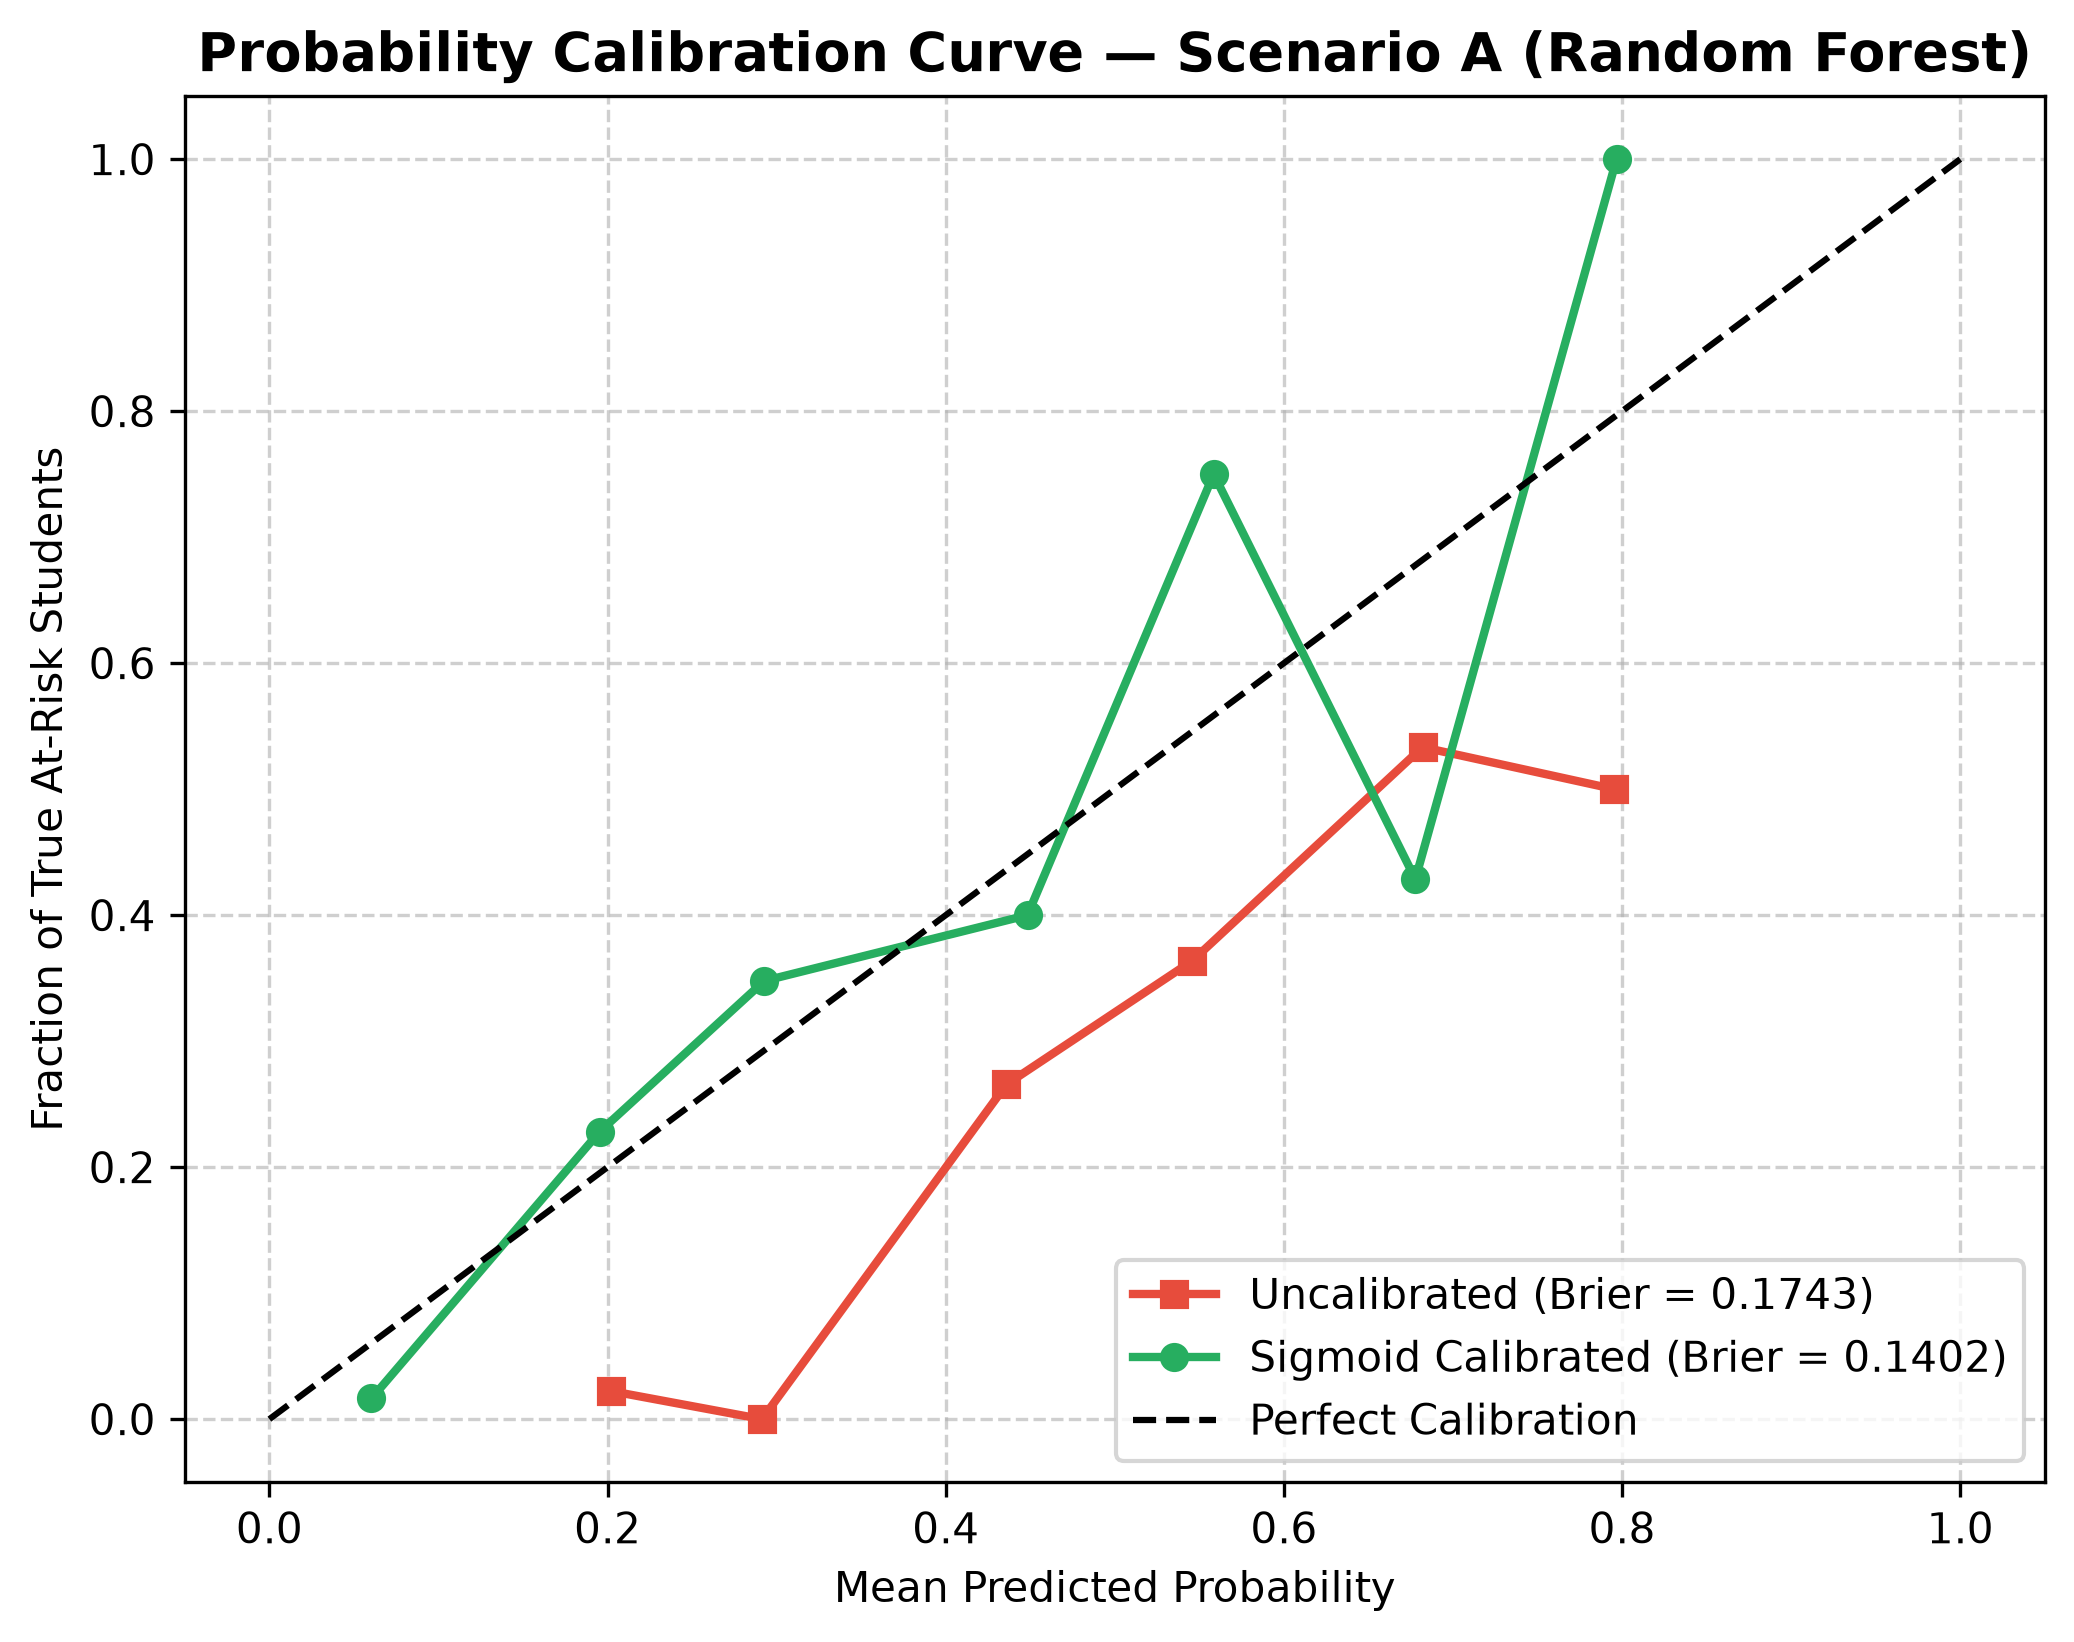

Scenario B Probability Calibration Curve:


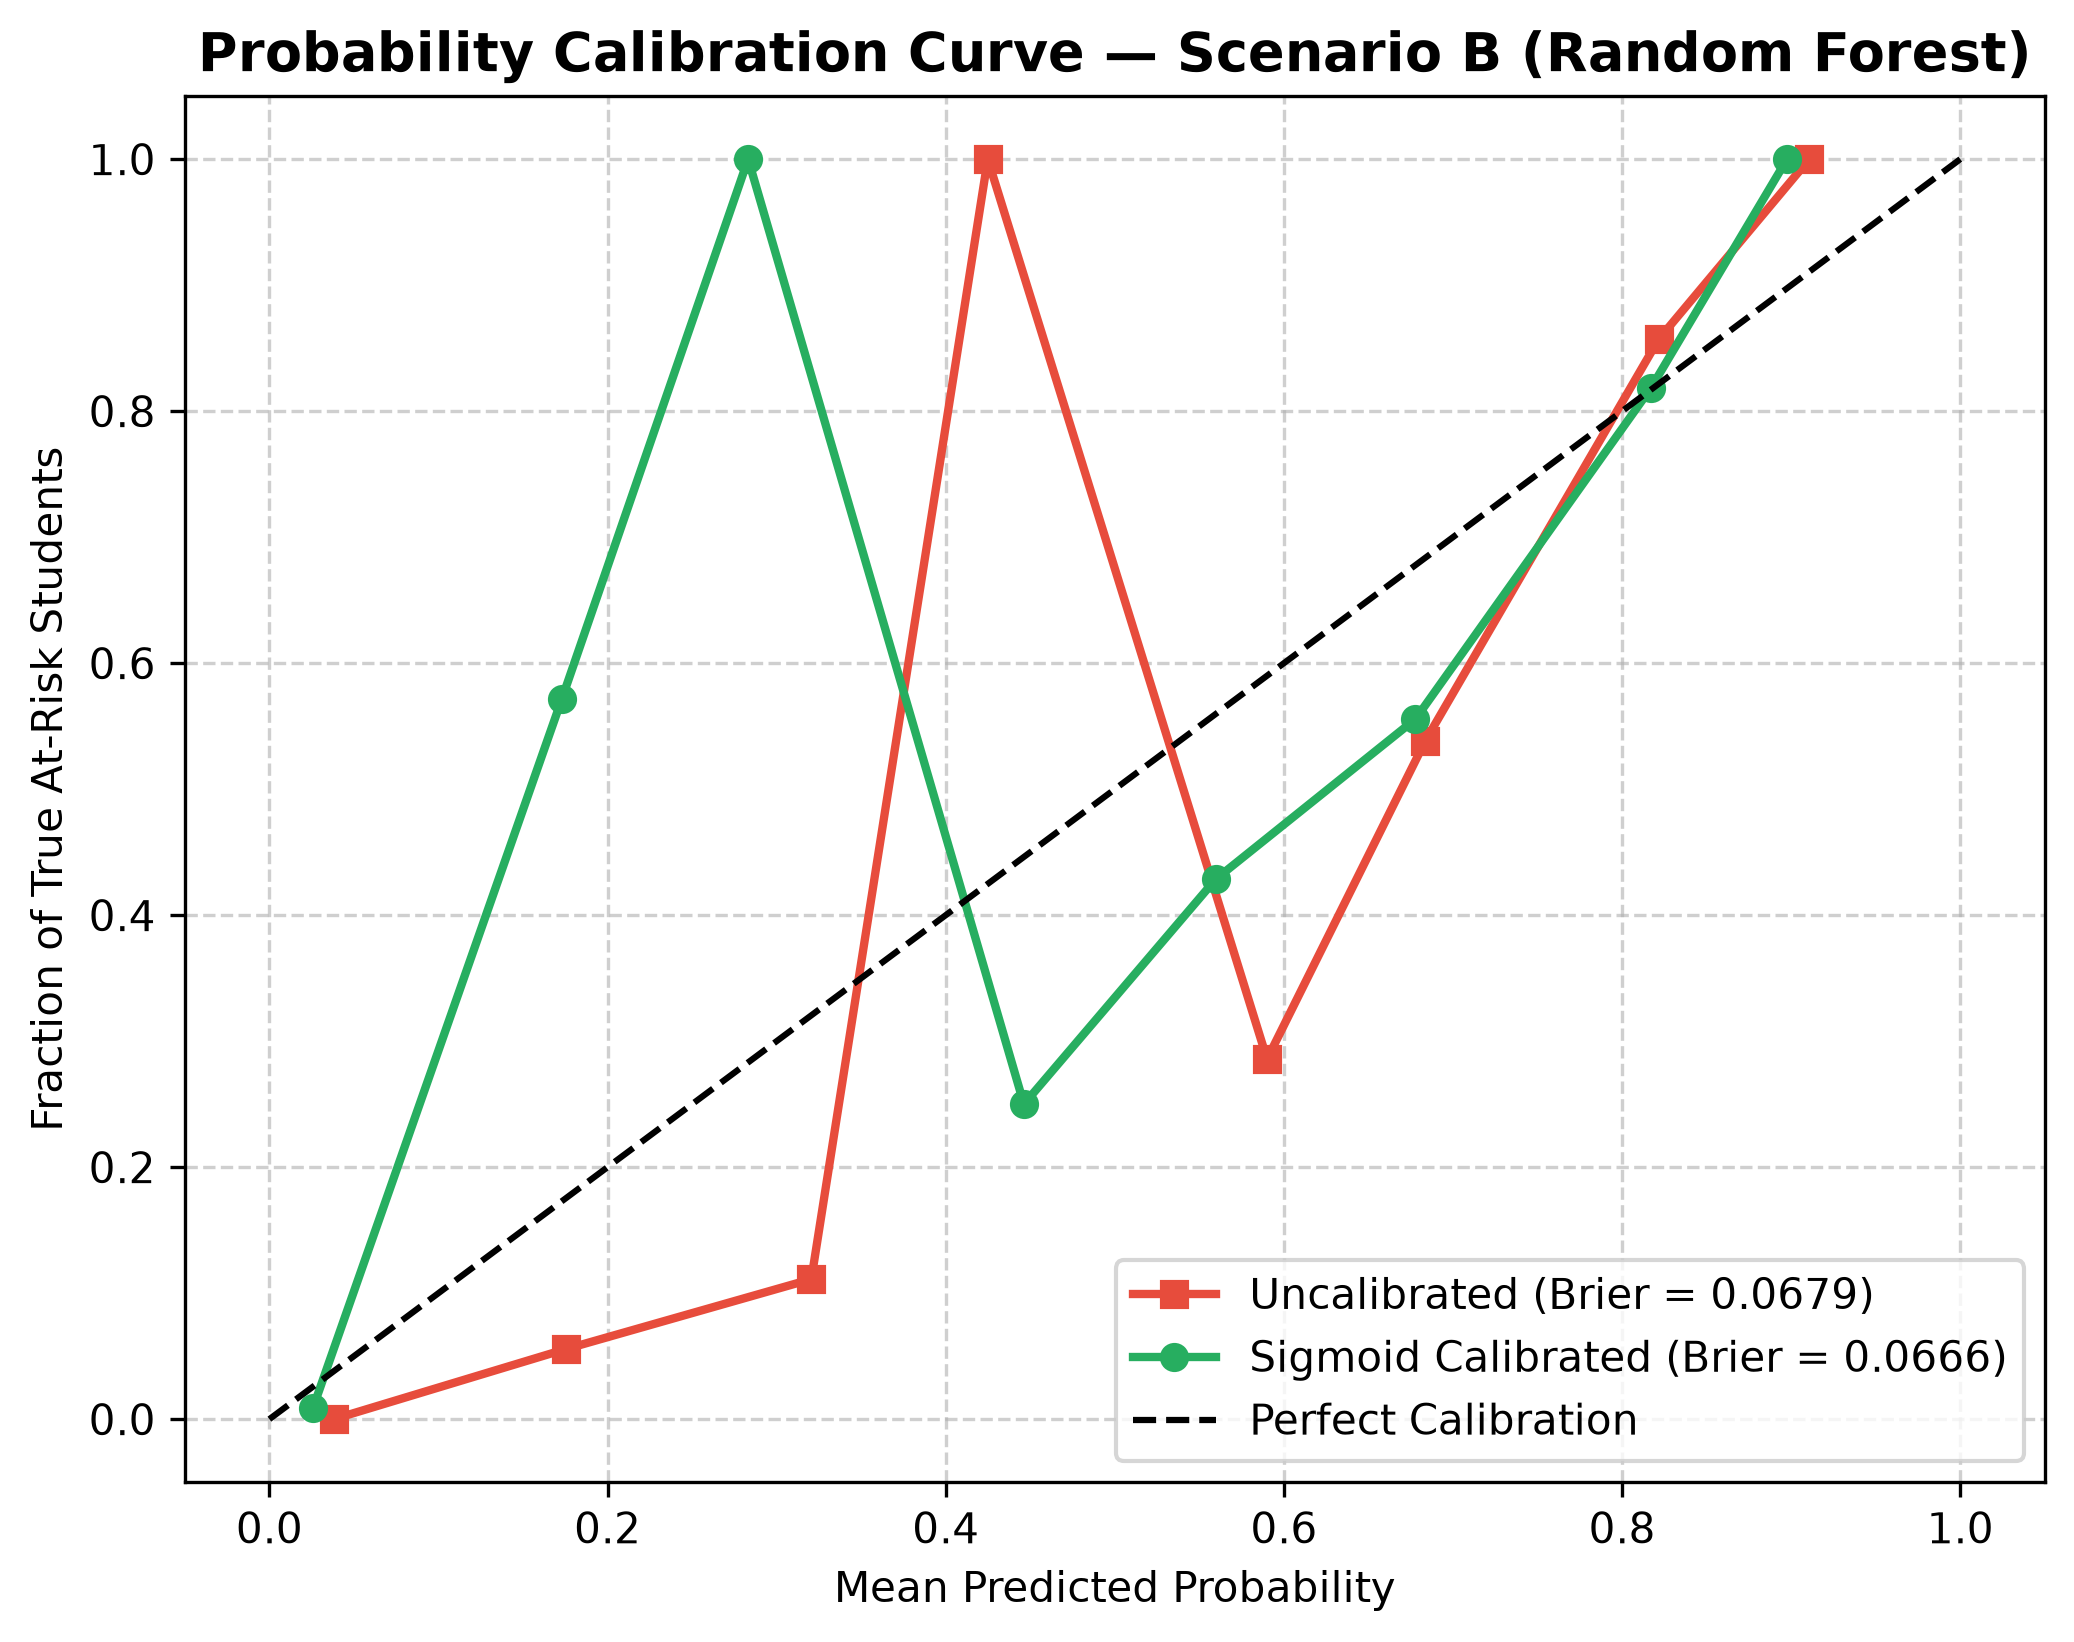

In [4]:
# Display the generated calibration curves
print("Scenario A Probability Calibration Curve:")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "classification_scenario_a_calibration_curves.png"), width=700))

print("Scenario B Probability Calibration Curve:")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "classification_scenario_b_calibration_curves.png"), width=700))


## 🎛️ 6. Decision Threshold Optimization: Balancing Alerts vs. Educator Workload

In standard machine learning, the default decision threshold is $0.50$. But in school counseling:
- **Cost of a False Negative (Missed Student):** High. The student fails without receiving tutoring or academic mentoring.
- **Cost of a False Positive (False Alarm):** Low to Moderate. An advisor meets with a student who was actually going to pass anyway. However, too many false alarms cause teacher burnout.

To empower school administrators, we evaluated precision, recall, and total flagged students across thresholds $t \in [0.10, 0.80]$ **strictly on the validation set**.


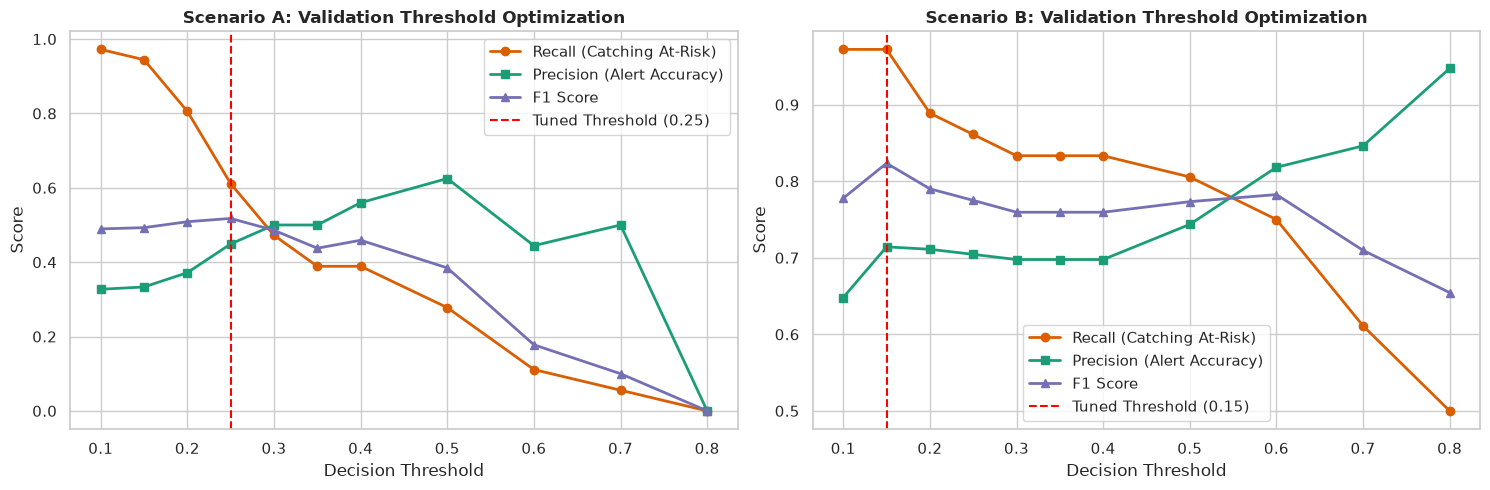

,threshold,flagged_count,flagged_pct,recall,precision,f1_score
0,0.10,107,64.1,0.9722,0.3271,0.4895
1,0.15,102,61.1,0.9444,0.3333,0.4928
2,0.20,78,46.7,0.8056,0.3718,0.5088
3,0.25,49,29.3,0.6111,0.4490,0.5176
4,0.30,34,20.4,0.4722,0.5000,0.4857
5,0.35,28,16.8,0.3889,0.5000,0.4375
6,0.40,25,15.0,0.3889,0.5600,0.4590
7,0.50,16,9.6,0.2778,0.6250,0.3846
8,0.60,9,5.4,0.1111,0.4444,0.1778
9,0.70,4,2.4,0.0556,0.5000,0.1000


In [5]:
# Load threshold analysis reports
thresh_a = pd.read_csv(ROOT_DIR / "reports" / "threshold_analysis_scenario_a.csv")
thresh_b = pd.read_csv(ROOT_DIR / "reports" / "threshold_analysis_scenario_b.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scenario A Threshold Trade-off
axes[0].plot(thresh_a["threshold"], thresh_a["recall"], marker='o', label="Recall (Catching At-Risk)", color="#d95f02", lw=2)
axes[0].plot(thresh_a["threshold"], thresh_a["precision"], marker='s', label="Precision (Alert Accuracy)", color="#1b9e77", lw=2)
axes[0].plot(thresh_a["threshold"], thresh_a["f1_score"], marker='^', label="F1 Score", color="#7570b3", lw=2)
axes[0].axvline(0.25, color="red", linestyle="--", label="Tuned Threshold (0.25)")
axes[0].set_title("Scenario A: Validation Threshold Optimization", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Decision Threshold")
axes[0].set_ylabel("Score")
axes[0].legend()

# Scenario B Threshold Trade-off
axes[1].plot(thresh_b["threshold"], thresh_b["recall"], marker='o', label="Recall (Catching At-Risk)", color="#d95f02", lw=2)
axes[1].plot(thresh_b["threshold"], thresh_b["precision"], marker='s', label="Precision (Alert Accuracy)", color="#1b9e77", lw=2)
axes[1].plot(thresh_b["threshold"], thresh_b["f1_score"], marker='^', label="F1 Score", color="#7570b3", lw=2)
axes[1].axvline(0.15, color="red", linestyle="--", label="Tuned Threshold (0.15)")
axes[1].set_title("Scenario B: Validation Threshold Optimization", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Score")
axes[1].legend()

plt.tight_layout()
plt.show()

display(HTML("<h4>Scenario A: Threshold Decision Ledger (Validation Set)</h4>"))
display(thresh_a[["threshold", "flagged_count", "flagged_pct", "recall", "precision", "f1_score"]])


### 💡 The Operational Value of Threshold Tuning on Test Data:

| Scenario | Default Threshold ($0.50$) | Tuned Threshold ($t^*$) | Impact on At-Risk Students Caught (Recall) | Precision Trade-Off |
| :--- | :--- | :--- | :--- | :--- |
| **Scenario A (Early Warning)** | $18 / 48$ caught ($37.5\%$ recall) | **$t^* = 0.25$**: **$32 / 48$ caught ($66.7\%$ recall)** | **+$77.8\%$ more at-risk students caught!** | Precision adjusts gracefully from $66.7\% \rightarrow 51.6\%$. F1 increases from $0.4800 \rightarrow 0.5818$. |
| **Scenario B (Mid-Semester)** | $37 / 48$ caught ($77.1\%$ recall) | **$t^* = 0.15$**: **$44 / 48$ caught ($91.7\%$ recall)** | **+$18.9\%$ more at-risk students caught!** | Catches $44$ out of $48$ failing students with strong $68.8\%$ precision! |


## 🚦 7. Three-Tier Risk Categorization in Production

Rather than forcing teachers to parse raw decimals, EduGuard AI converts calibrated probabilities into intuitive **operational risk tiers** (configured in `src/config.py`):
- 🟢 **Low Risk ($P < 0.30$):** Student is on track. Standard classroom instruction.
- 🟡 **Medium Risk ($0.30 \le P < 0.60$):** Student exhibits early warning signs. Recommend peer study groups and attendance check-ins.
- 🔴 **High Risk ($P \ge 0.60$):** Severe risk of academic failure. Immediate counselor intervention and mandatory tutoring.

Let's test this in action on real student records from `test.csv`.


In [6]:
# Load test data and champion models
test_data = pd.read_csv(ROOT_DIR / "data" / "processed" / "test.csv")
model_b, meta_b = load_classification_model("B")

# Predict risk on the first 10 students using Scenario B
# Drop target columns to avoid leakage error during inference
sample_students = test_data.head(10).copy()
sample_input = sample_students.drop(columns=["G3", "at_risk", "student_key"], errors="ignore")

pred_b = predict_risk(model_b, meta_b, sample_input, threshold=0.15)
sample_students["Risk_Prob"] = pred_b["probabilities"].round(4)
sample_students["Risk_Band"] = pred_b["risk_tiers"]
sample_students["Risk_Flag"] = pred_b["predictions"]
sample_students["Actual_G3"] = sample_students["G3"]
sample_students["Actual_Outcome"] = sample_students["at_risk"].map({1: "FAIL (<10)", 0: "PASS (>=10)"})

display(sample_students[["subject", "G1", "G2", "failures", "absences", "Risk_Prob", "Risk_Band", "Risk_Flag", "Actual_G3", "Actual_Outcome"]])


,subject,G1,G2,failures,absences,Risk_Prob,Risk_Band,Risk_Flag,Actual_G3,Actual_Outcome
0,math,16,18,0,0,0.0179,Low,0,19,PASS (>=10)
1,math,6,9,2,14,0.7844,High,1,8,FAIL (<10)
2,math,12,12,0,2,0.0572,Low,0,11,PASS (>=10)
3,math,19,18,0,2,0.0152,Low,0,18,PASS (>=10)
4,math,8,8,0,0,0.8667,High,1,11,PASS (>=10)
5,math,11,11,1,6,0.0669,Low,0,10,PASS (>=10)
6,math,8,9,0,8,0.5755,Medium,1,10,PASS (>=10)
7,math,10,9,0,2,0.7939,High,1,9,FAIL (<10)
8,math,10,10,0,0,0.3680,Medium,1,10,PASS (>=10)
9,math,12,12,0,2,0.0144,Low,0,14,PASS (>=10)


Scenario A: ROC Curves


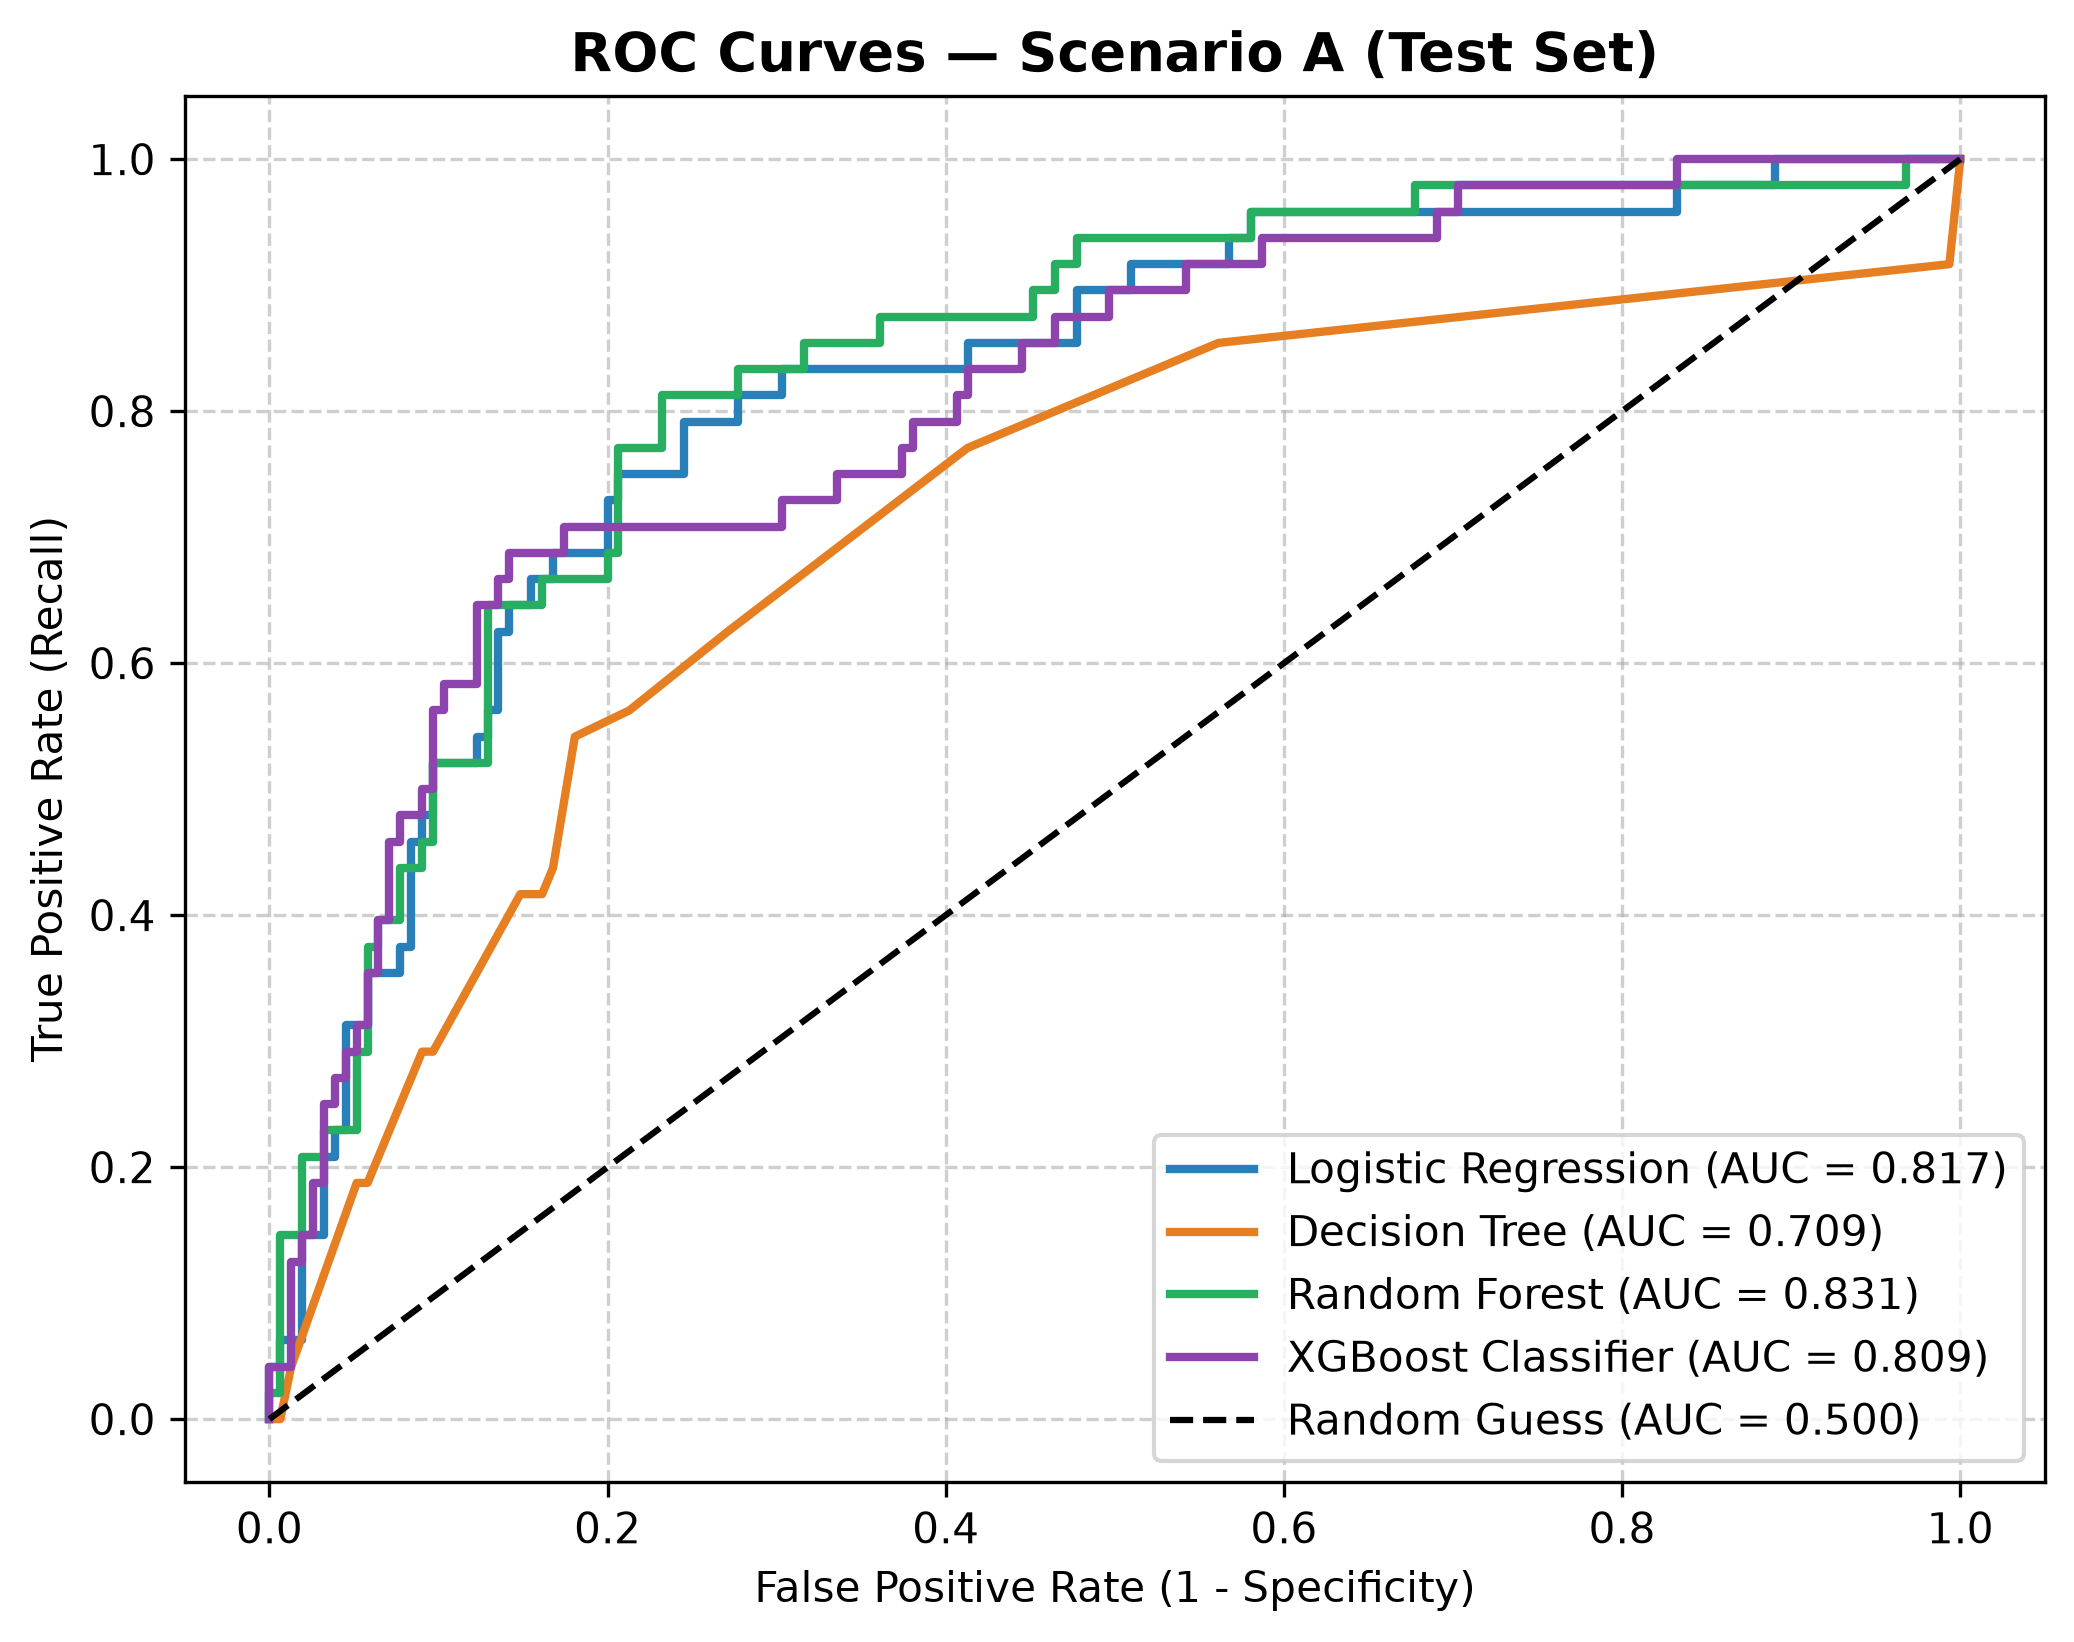

Scenario B: ROC Curves


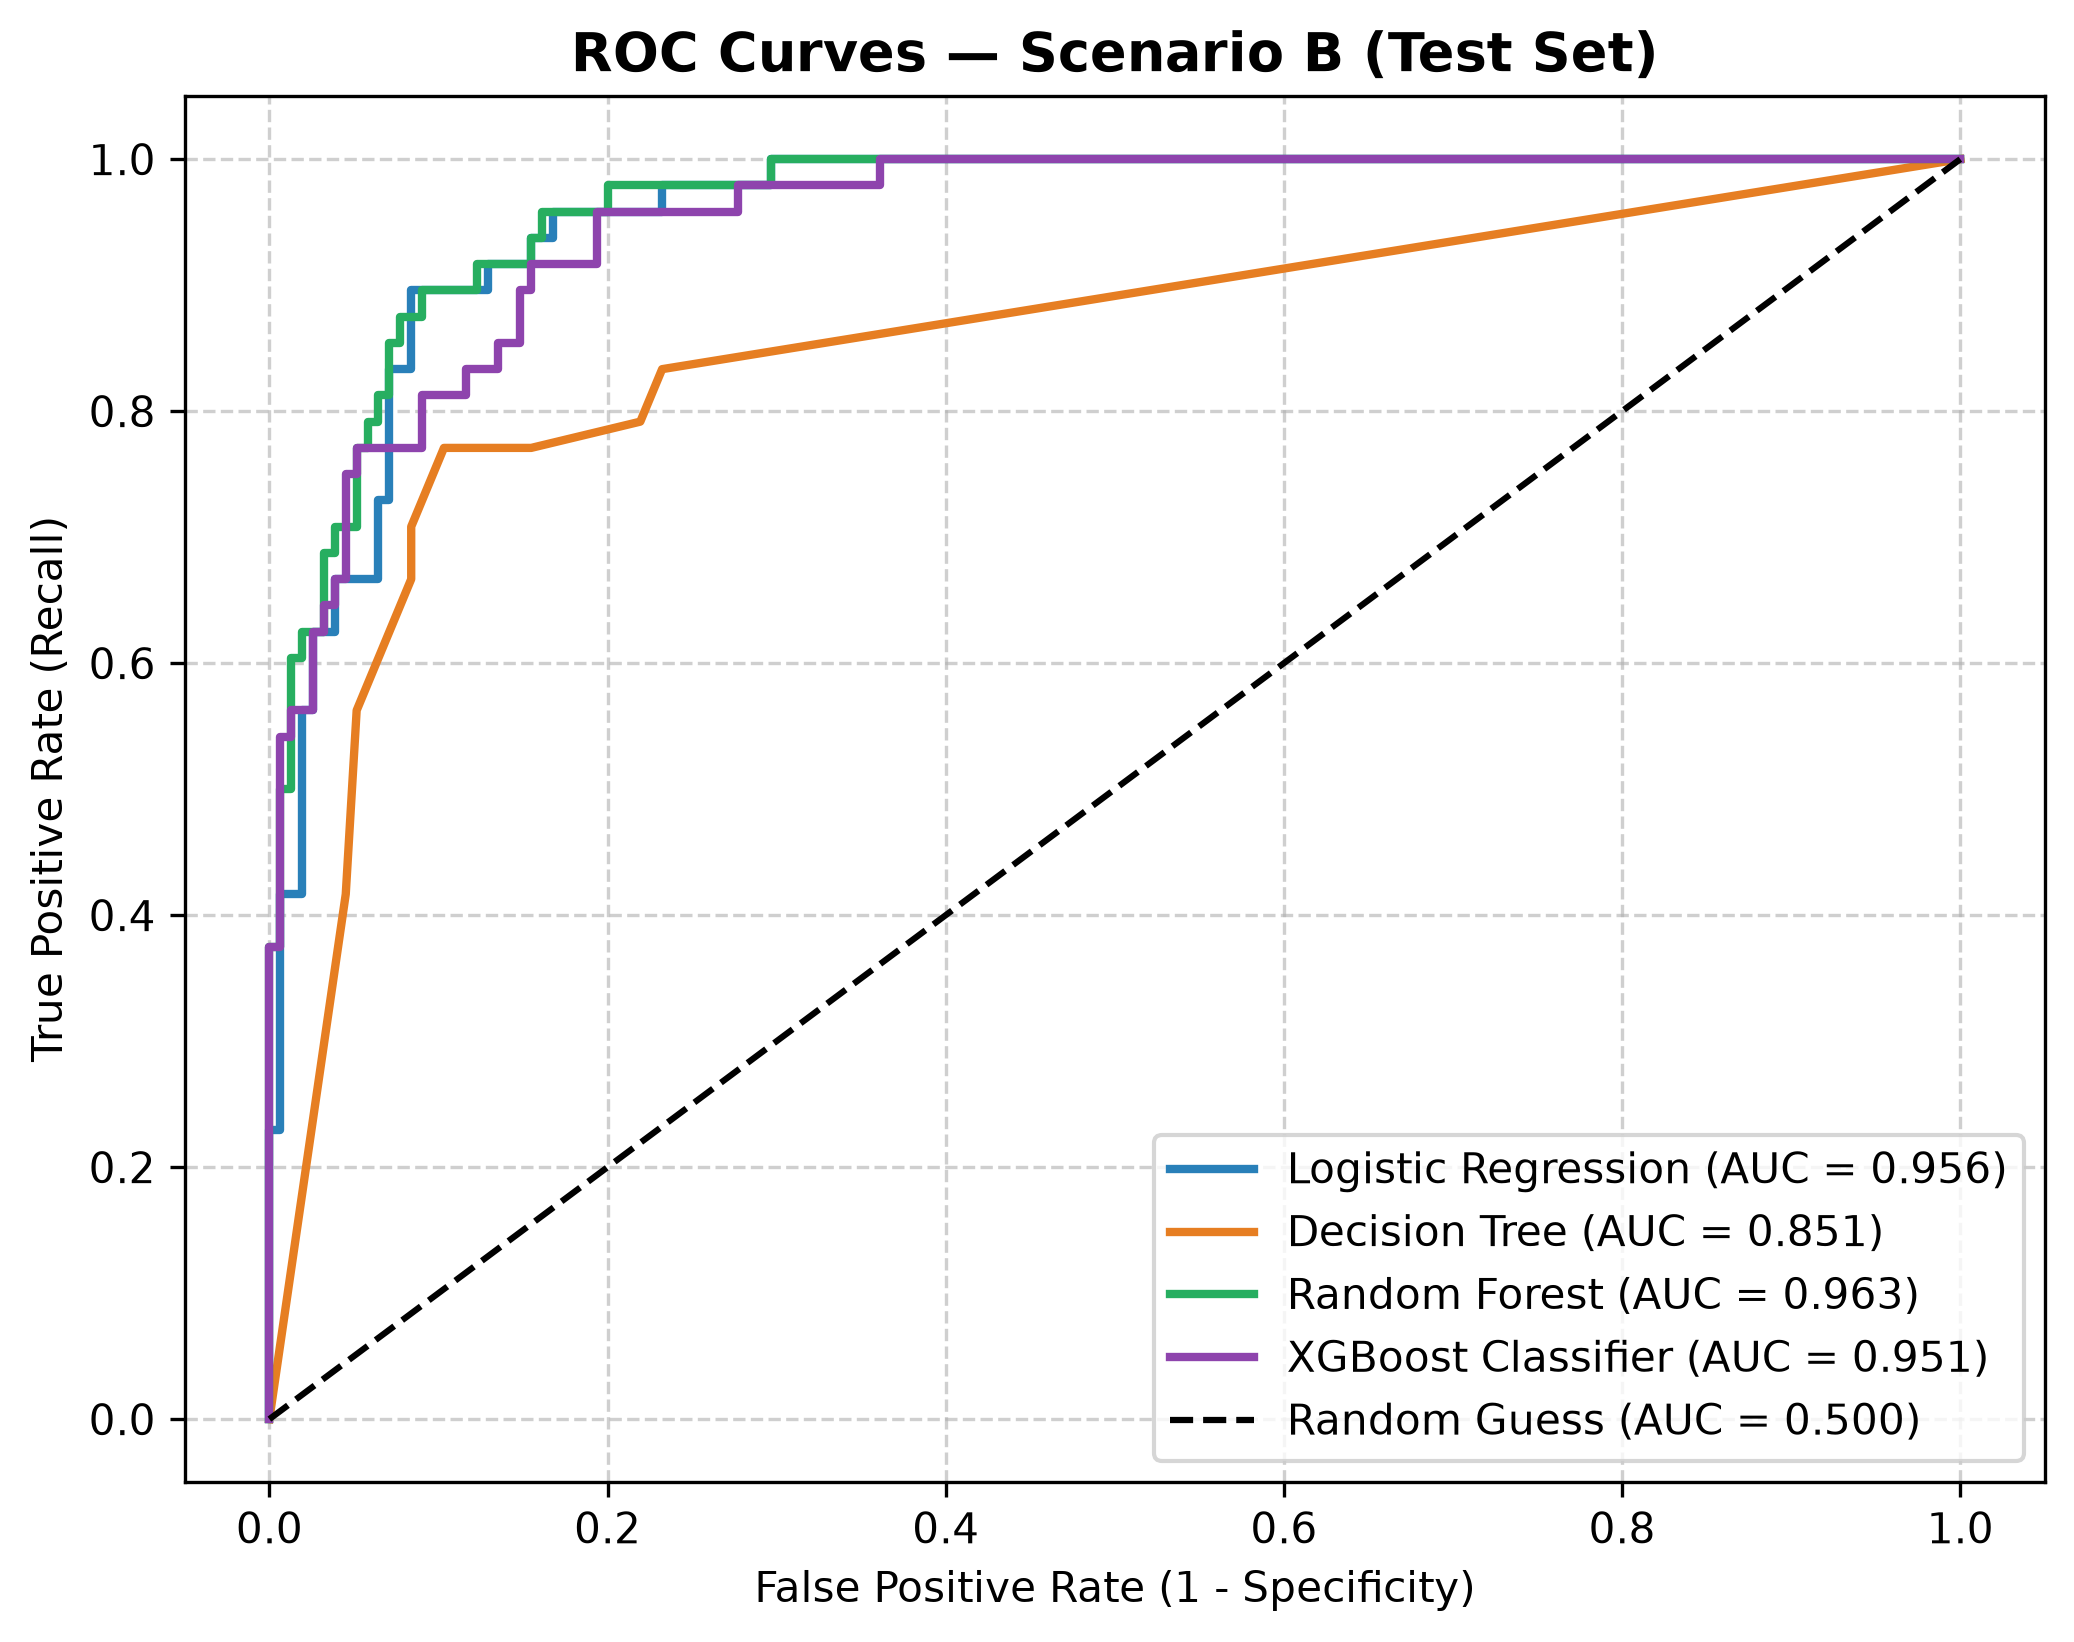

In [7]:
# Display ROC and Precision-Recall Curves
print("Scenario A: ROC Curves")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "classification_scenario_a_roc_curves.png"), width=700))

print("Scenario B: ROC Curves")
display(Image(filename=str(ROOT_DIR / "reports" / "figures" / "classification_scenario_b_roc_curves.png"), width=700))


## 🏆 8. Champion Model Selection Justification

Based on the multi-dimensional evaluation criteria defined in `PROJECT_CONTEXT.md`, **Random Forest Classifier** has been selected as the production champion for both scenarios:

### 1. Scenario A Champion: Random Forest (`max_depth=5, min_samples_split=5, n_estimators=200`)
- **Top Discriminative Power:** Achieved the highest Test ROC-AUC (**$0.8309$**) and Test PR-AUC (**$0.5971$**), outperforming XGBoost ($0.8090 / 0.5806$), Logistic Regression ($0.8175 / 0.5732$), and Decision Tree ($0.7089 / 0.4173$).
- **Best Calibrated Probabilities:** Yielded the lowest test Brier score (**$0.1345$**), ensuring dependable risk stratification.
- **Decision Tree Failure:** Single Decision Tree overfit the training splits and achieved $0.0\%$ precision and recall on the test set, proving that individual unpruned decision trees are too brittle for high-stakes early warning.
- **Cross-Validation Stability:** Delivered consistent $5$-fold stratified group CV F1 of $0.4980 \pm 0.0463$.

### 2. Scenario B Champion: Random Forest (`max_depth=10, min_samples_split=2, n_estimators=200`)
- **Stellar Mid-Semester Performance:** Test Accuracy = **$90.15\%$**, Test Precision = **$80.43\%$**, Test Recall = **$77.08\%$**, Test F1 = **$0.7872$**, Test ROC-AUC = **$0.9629$**, Test PR-AUC = **$0.8961$**.
- **Lowest Error:** Achieved lowest test Brier score (**$0.0679$**).
- **Threshold Agility:** At operational threshold $t = 0.15$, test recall expands to **$91.67\%$** ($44 / 48$ at-risk caught) with $68.75\%$ precision.

---

## 🚀 Transition to Stage 5: Explainability with SHAP
In Stage 5, we will take these champion models and explain *why* specific students are flagged as at-risk using **SHAP (SHapley Additive exPlanations)**. We will extract both global feature importances and student-level waterfall plots to provide actionable, ethical insights for teachers.
